## MIE360 Fall 2026 Project: Hospital Modeling and Simulation
### Deliverable 3.1: Input Modeling

Signatures
|Student|ID|
|-------|--|
|Gabriel Faustino|1011376823|
|Sunny Wu|1010978239|
|Benjamin Zhou||

**Note: It is recommended to use a virtual environment (venv) before installing the required modules.** Run `python -m venv .venv` and `./.venv/Scripts/activate` before installing the required modules.

**Note: this notebook is designed to run with the locally-installed CSV data files after cloning.** Run `pip install -r ./deps/requirements.txt` before running.

In [40]:
import pandas as pd
import numpy as np
import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

### Visualizing and modeling arrival times

In [41]:
# Read arrivals data. Use the Day# column (idx 0) as the index.

df_arrivals = pd.read_csv("./data/Data_Arrivals.csv", index_col=0)
display(df_arrivals.head(5))
display(df_arrivals.shape)

,1am,2am,3am,4am,5am,6am,7am,8am,9am,10am,...,3pm,4pm,5pm,6pm,7pm,8pm,9pm,10pm,11pm,12am
Day1,0,0,2,1,0,0,0,2,1,4,...,3,2,1,7,4,5,2,3,4,2
Day2,3,2,1,0,0,0,0,0,3,1,...,3,4,6,6,2,2,3,2,3,3
Day3,1,0,2,1,0,1,1,2,3,0,...,4,5,8,7,4,3,1,2,2,4
Day4,1,0,0,1,0,2,0,5,2,2,...,4,2,3,8,4,8,3,3,3,5
Day5,1,2,0,1,1,1,2,1,1,1,...,8,2,10,5,6,2,3,3,4,3


(100, 24)

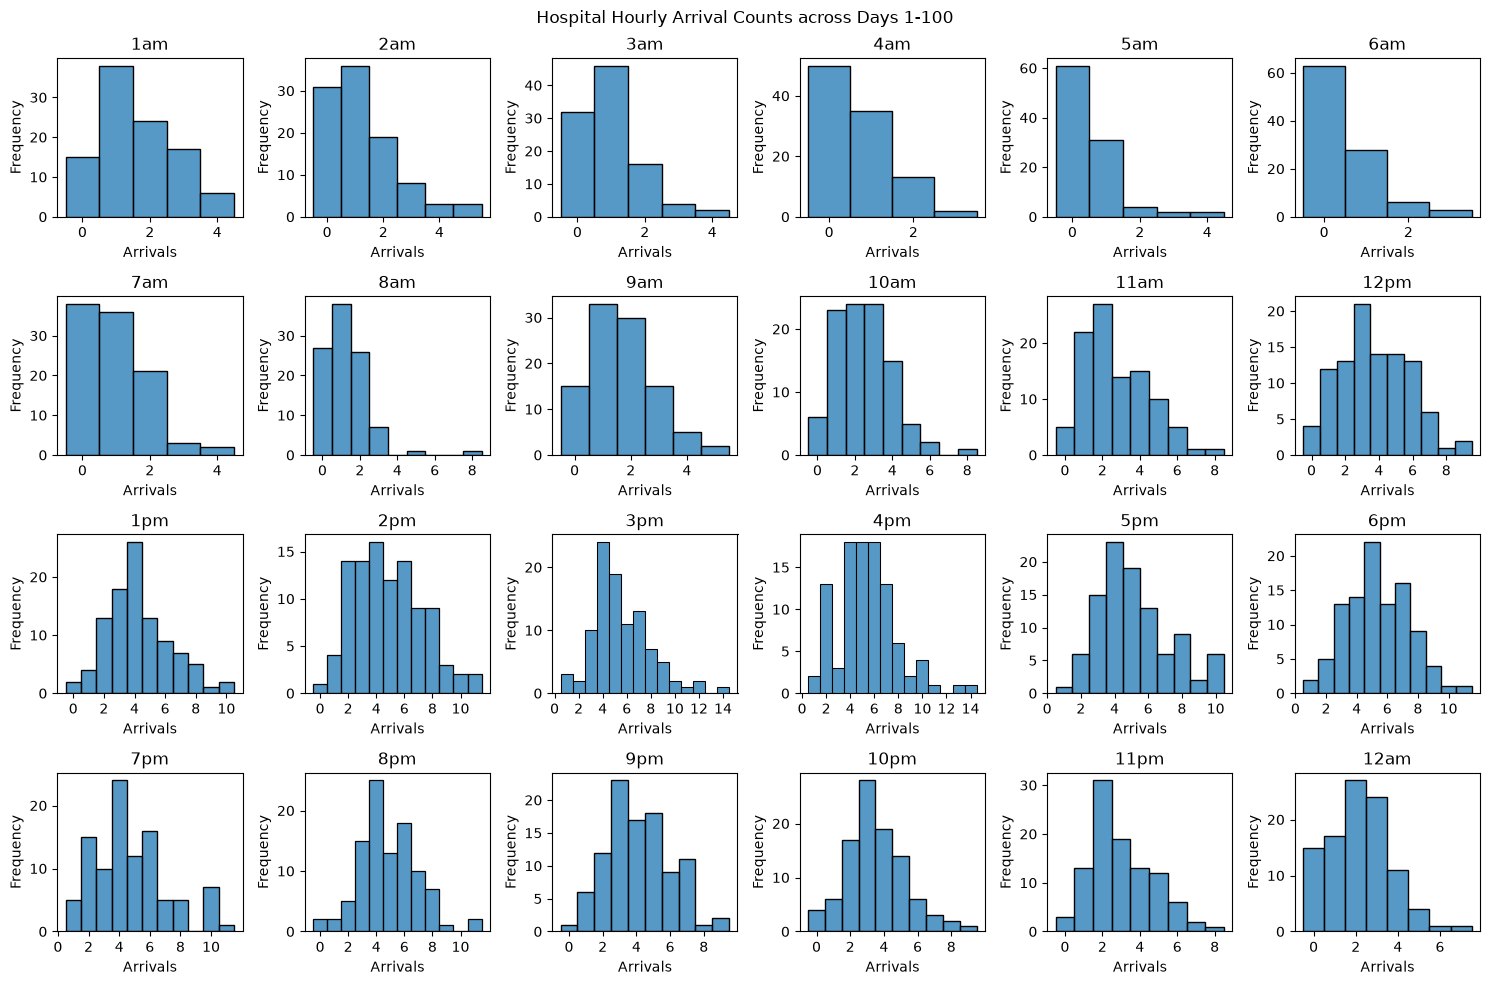

In [42]:
fig, axes = plt.subplots(4, 6, figsize=(15, 10))
fig.suptitle("Hospital Hourly Arrival Counts across Days 1-100")

axes = axes.flat
for i, col_name in enumerate(df_arrivals.columns):
    ax = axes[i]
    x = df_arrivals[col_name]
    sns.histplot(data=x, discrete=True, ax=ax)
    ax.set_ylabel("Frequency")
    ax.set_xlabel("Arrivals")
    ax.set_title(col_name)
    ax.set_xticks(np.arange(0, x.max() + 1, 2))

plt.tight_layout()
plt.show()

Visual observation of the data suggests that 24 independent Poisson distributions are a likely fit for each hour, since:
1. it seems reasonable to assume that arriving hospital cases are independent, and
2. the data appears to exhibit right skew, which Poisson exhibits.

both of which are good reasons to try fitting all arrival distributions with Poisson distributions, which are often used to model independent arrivals.

In [43]:
# Calculate Poisson MLEs (sample mean) for each hour
poisson_mles = df_arrivals.sum(axis=0)/df_arrivals.shape[0]
display(poisson_mles)

1am     1.61
2am     1.25
3am     0.98
4am     0.67
5am     0.53
6am     0.49
7am     0.95
8am     1.24
9am     1.68
10am    2.48
11am    2.73
12pm    3.73
1pm     4.25
2pm     4.86
3pm     5.55
4pm     5.42
5pm     5.15
6pm     5.36
7pm     4.73
8pm     4.87
9pm     4.14
10pm    3.52
11pm    3.02
12am    2.20
dtype: float64

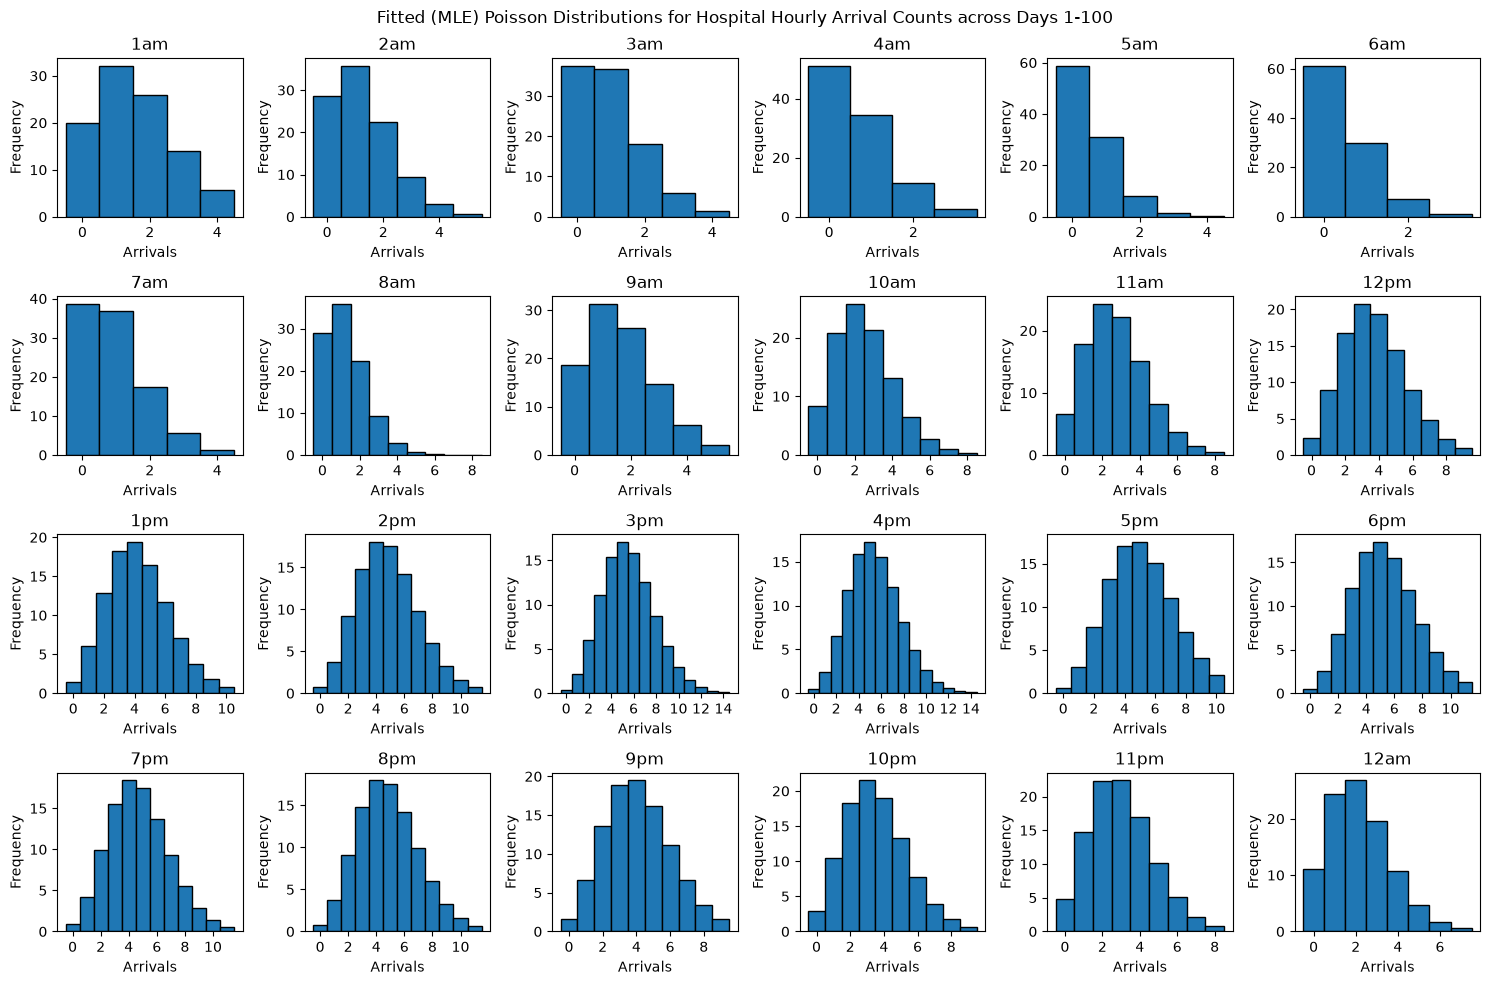

In [44]:
# TODO Display scaled poisson distribution over visualization to quickly confirm if poisson is a good fit for modeling.
from scipy.stats import poisson

poisson_distributions = [poisson(mu=rate) for rate in poisson_mles]

fig, axes = plt.subplots(4, 6, figsize=(15, 10))
fig.suptitle("Fitted (MLE) Poisson Distributions for Hospital Hourly Arrival Counts across Days 1-100")

for ax, col_name, poisson_dist in zip(axes.flat, df_arrivals.columns, poisson_distributions):
    x = np.arange(0, df_arrivals[col_name].max() + 1) # bins
    ax.bar(x, poisson_dist.pmf(x) * 100, edgecolor='black', width=1.0)
    ax.set_ylabel("Frequency")
    ax.set_xlabel("Arrivals")
    ax.set_title(col_name)
    ax.set_xticks(np.arange(0, df_arrivals[col_name].max() + 1, 2))

fig.tight_layout()

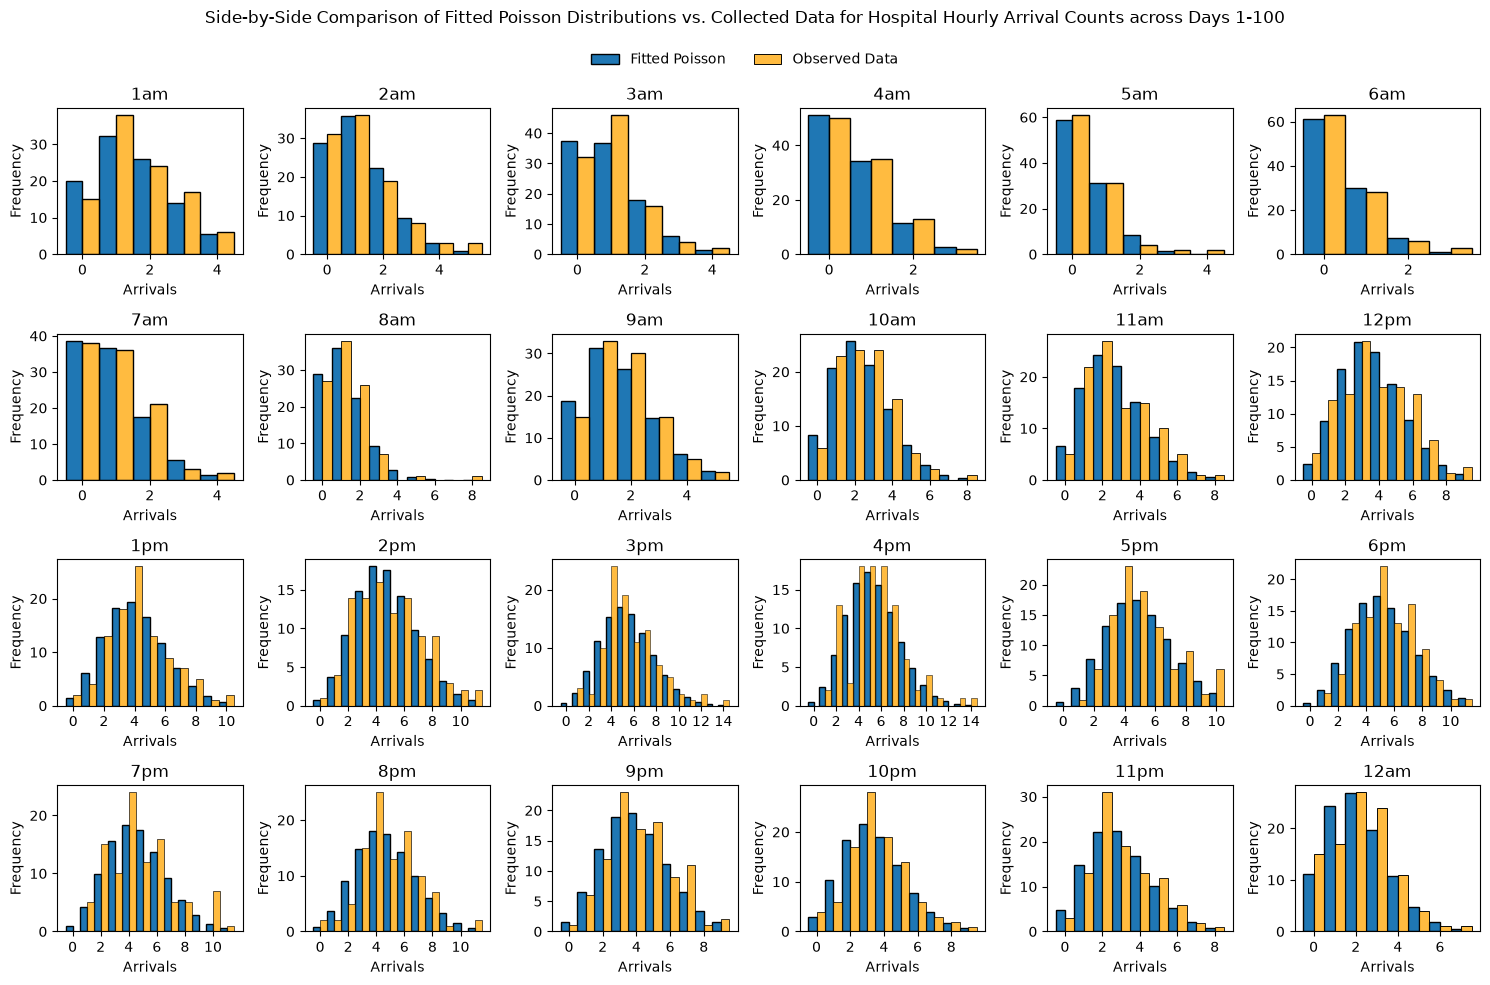

In [45]:
# Display the fitted Poisson distributions over the histograms of the actual data

fig, axes = plt.subplots(4, 6, figsize=(15, 10))
fig.suptitle("Side-by-Side Comparison of Fitted Poisson Distributions vs. Collected Data for Hospital Hourly Arrival Counts across Days 1-100")

for ax, col_name, poisson_dist in zip(axes.flat, df_arrivals.columns, poisson_distributions):

    # Plot poisson
    x1 = np.arange(0, df_arrivals[col_name].max() + 1) # number of possible arrivals in a specific hour
    ax.bar(x1 - 0.25, poisson_dist.pmf(x1) * 100, edgecolor='black', width=0.5, label="Fitted Poisson")

    # Plot histogram
    x2 = df_arrivals[col_name]
    sns.histplot(data=x2+0.25, discrete=True, ax=ax, color='orange', shrink=0.5, label="Observed Data")

    ax.set_ylabel("Frequency")
    ax.set_xlabel("Arrivals")
    ax.set_title(col_name)
    ax.set_xticks(np.arange(0, df_arrivals[col_name].max() + 1, 2))

handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.95), ncol=2, frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [46]:
# Run chi-squared test of observed arrival counts versus proposed Poisson distribution

from scipy.stats import chisquare

results = {}
for col_name, poisson_dist in zip(df_arrivals.columns, poisson_distributions):
    # Get observed counts
    observed_counts = df_arrivals[col_name].value_counts().sort_index()
    
    # Get expected counts from Poisson distribution
    x = np.arange(0, df_arrivals[col_name].max() + 1)
    expected_counts = poisson_dist.pmf(x) * observed_counts.sum()

    # add the tail probability to the last bin to last bin so that the expected counts sum to the total number of observations
    expected_counts[-1] += poisson_dist.sf(x[-1]) * observed_counts.sum() 
    
    # Align observed and expected counts by realigning the observed counts to the expected counts index
    observed_counts_aligned = observed_counts.reindex(x, fill_value=0)
    
    # Perform chi-squared test, ddof=1 to account for the estimated parameter (lambda)
    chi2_stat, p_value = chisquare(f_obs=observed_counts_aligned, f_exp=expected_counts, ddof=1) 
    
    results[col_name] = {
        'chi2_stat': chi2_stat,
        'p_value': p_value,
        'observed_counts': observed_counts_aligned,
        'expected_counts': expected_counts
    }

# 95% confidence level, so alpha = 0.05
alpha = 0.05
H_0_rejected = []
p_values_rejected_by_hour = pd.DataFrame(columns=["p_value"])

for col_name, result in results.items():
    if result['p_value'] < alpha:
        H_0_rejected.append(1)
        p_values_rejected_by_hour.loc[col_name] = [result["p_value"]]

percent_H_0_rejected = sum(H_0_rejected) / len(results) * 100

# Poisson distribution is a good fit in most cases. 
print(f"Percentage of hours where H_0 is rejected: {percent_H_0_rejected:.2f}%")
print(f"Hours where H_0 is rejected, with p-values:")
display(p_values_rejected_by_hour)

Percentage of hours where H_0 is rejected: 16.67%
Hours where H_0 is rejected, with p-values:


,p_value
5am,6.379222e-04
8am,1.748852e-43
4pm,2.223076e-02
7pm,4.351399e-05


### Analysis of arrival modeling
Visually, the MLE Poisson distribution appears to largely fit most of the observed data, with a few histogram bins vastly differing. Our $\chi^2$ test conducted above largely agrees with this qualitative observation, showing that the MLE Poisson distribution is an acceptable fit for the majority (20/24) of the hours at the $\alpha=0.05$ confidence level.

We note that the $\chi^2$ test fails the following arrival periods at the $\alpha=0.05$ confidence level:
- 5 AM ($p=6.38\times10^{-4}$)
- 8 AM ($p=1.75\times10^{-43}$)
- 4 PM ($p=2.22\times10^{-2}$)
- 7 PM ($p=4.35\times10^{-5}$)

On visual inspection, the failing hours appear to be:
- noisy (4 PM and 7 PM), or
- have outliers that distort the test (5 AM, 8 PM, 7 PM).

[TODO need more formal justification.]

We believe that bar these disrepancies, an all-Poisson approach across all 24 hours is still appropriate for our input modeling.

### Visualizing and modeling service times

In [47]:
# Read treatment (service) time data. Use the ID column (idx 0) as the index.
df_treatment_raw = pd.read_csv("./data/Data_TreatmentTimes.csv", index_col=0)
df_treatment_raw = df_treatment_raw.rename(columns={"Treatment Time (Days)": "TreatmentTime"})
display(df_treatment_raw.head(5))
display(df_treatment_raw.shape)
print(df_treatment_raw["Specialty"].unique())

,TreatmentTime,Specialty
ID,,
0,4.640229,Ortho
1,0.770322,Renal
2,1.911212,Card
3,4.199311,Respi
4,2.527663,Gastro_Endo


(18565, 2)

<StringArray>
['Ortho', 'Renal', 'Card', 'Respi', 'Gastro_Endo']
Length: 5, dtype: str


In [48]:
# Group treatment time data by specialty.
# We assume that the treatment time distribution for a given specialty is the same across all wards under that specialty.
# (We are not given information about service times in each ward.)
df_treatment_by_specialty = df_treatment_raw.groupby(["Specialty"])
display(df_treatment_by_specialty.describe())

TreatmentTime                                              \
                    count      mean       std           min       25%   
Specialty                                                               
Card               4321.0  2.884995  3.515021  5.928158e-02  0.926157   
Gastro_Endo        3254.0  3.375186  3.639022  6.806160e-04  0.815995   
Ortho              3425.0  5.490906  5.491733  3.238330e-04  1.549496   
Renal              3244.0  4.823262  6.828324  2.105476e-07  0.517170   
Respi              4321.0  3.296486  5.696918  4.035753e-02  0.782429   

                                             
                  50%       75%         max  
Specialty                                    
Card         1.774205  3.454252   42.392131  
Gastro_Endo  2.188181  4.703748   28.626801  
Ortho        3.861794  7.595541   52.501056  
Renal        2.228971  6.244268   59.849193  
Respi        1.747665  3.666749  143.763709

In [49]:
# Peek the grouping
for i, (group_name, df_group) in enumerate(df_treatment_by_specialty):
    display(group_name[0])
    display(df_group.head(5))

'Card'

,TreatmentTime,Specialty
ID,,
2,1.911212,Card
5,2.076513,Card
6,1.862886,Card
14,1.343026,Card
17,5.331829,Card


'Gastro_Endo'

,TreatmentTime,Specialty
ID,,
4,2.527663,Gastro_Endo
18,2.758086,Gastro_Endo
27,10.760506,Gastro_Endo
44,0.495989,Gastro_Endo
47,10.935222,Gastro_Endo


'Ortho'

,TreatmentTime,Specialty
ID,,
0,4.640229,Ortho
15,0.653278,Ortho
20,1.716359,Ortho
24,0.549169,Ortho
25,9.000257,Ortho


'Renal'

,TreatmentTime,Specialty
ID,,
1,0.770322,Renal
7,0.001040,Renal
10,11.152471,Renal
11,3.017819,Renal
12,2.317516,Renal


'Respi'

,TreatmentTime,Specialty
ID,,
3,4.199311,Respi
8,0.213762,Respi
9,0.271861,Respi
13,1.609639,Respi
16,9.681560,Respi


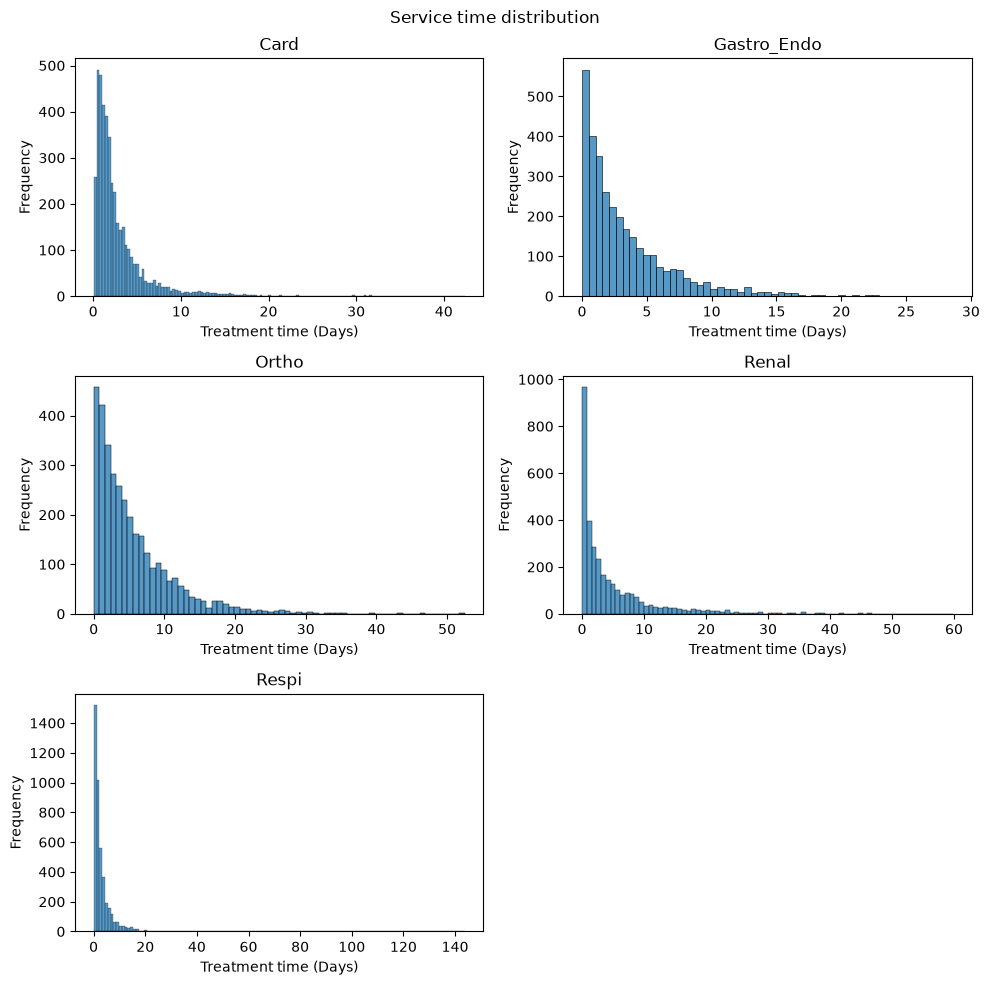

In [50]:
# Visualize treatment time data by speciality in histograms. (Preliminary.)
fig, axes = plt.subplots(3, 2, figsize=(10, 10))
fig.suptitle("Service time distribution")

axes = axes.flat
for i, (group_name, df_group) in enumerate(df_treatment_by_specialty):
    ax = axes[i]
    sns.histplot(data=df_group["TreatmentTime"], ax=ax)
    ax.set_ylabel("Frequency")
    ax.set_xlabel("Treatment time (Days)")
    ax.set_title(group_name[0])

for ax in axes[i+1:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## Compare gamma, exponential, and lognormal distributions

In [51]:
# MLEs for gamma distribution
gamma_mles = {}
for group_name, df_group in df_treatment_by_specialty:
    # Fit gamma distribution to the treatment time data for this specialty
    shape, loc, scale = stats.gamma.fit(df_group["TreatmentTime"], floc=0)  # Fix location to 0
    gamma_mles[group_name[0]] = (shape, loc, scale)

# MLEs for exponential distribution
exponential_mles = {}
for group_name, df_group in df_treatment_by_specialty:
    # Fit exponential distribution to the treatment time data for this specialty
    loc, scale = stats.expon.fit(df_group["TreatmentTime"], floc=0)  # Fix location to 0
    exponential_mles[group_name[0]] = (loc, scale)

# MLEs for lognormal distribution
lognormal_mles = {}
for group_name, df_group in df_treatment_by_specialty:  
    # Fit lognormal distribution to the treatment time data for this specialty
    shape, loc, scale = stats.lognorm.fit(df_group["TreatmentTime"], floc=0)  # Fix location to 0
    lognormal_mles[group_name[0]] = (shape, loc, scale)

gamma_mles


{'Card': (1.170541810496347, 0, np.float64(2.4646661432045325)),
 'Gastro_Endo': (0.8466957605437156, 0, np.float64(3.9863037301331734)),
 'Ortho': (1.0147367271709278, 0, np.float64(5.411163405986773)),
 'Renal': (0.5121985074122511, 0, np.float64(9.416782989343686)),
 'Respi': (0.8973004097766168, 0, np.float64(3.6737819516631847))}

In [52]:
# Chi-squared test for goodness of fit for each distribution and each specialty
# e.g., Ortho and log, ortho and gamma, ortho and exponential, etc.

gamma_results = {}
exponential_results = {}
lognormal_results = {}

# Integers represent ddof: 2 parameters being estimated for gamma and lognormal, 1 parameter for exponential
models = [("Gamma", stats.gamma, gamma_mles, 2, gamma_results), ("Exponential", stats.expon, exponential_mles, 1, exponential_results), ("Lognormal", stats.lognorm, lognormal_mles, 2, lognormal_results)]

for group_name, df_group in df_treatment_by_specialty:
    specialty = group_name[0] 
    times = df_group["TreatmentTime"]
    n = len(times) # Number of observations for this specialty

    # Obtain appropriate bin number. Use up to 10 bins with at least 5 expected observations each.
    n_bins = max(1, min(10, n // 5))

    # Quantiles of the fitted distribution will be used to create bins for the chi-squared test.
    quantiles = np.linspace(0, 1, n_bins + 1)[1:-1]

    for _, distribution, mles, ddof, results in models:
        # extract MLEs for the current specialty and fit the distribution
        fitted_dist = distribution(*mles[specialty]) 

        bin_edges = np.r_[-np.inf, fitted_dist.ppf(quantiles), np.inf]

        observed_counts, _ = np.histogram(times, bins=bin_edges)

        # difference in CDF values at bin edges gives the expected proportion of observations 
        # in each bin, multiplied by n gives expected counts
        expected_counts = n * np.diff(fitted_dist.cdf(bin_edges)) 
        chi2_stat, p_value = chisquare(f_obs=observed_counts, f_exp=expected_counts, ddof=ddof)

        # Store results for this specialty and distribution
        results[specialty] = {"chi2_stat": chi2_stat, "p_value": p_value, "observed_counts": observed_counts, "expected_counts": expected_counts, "bin_edges": bin_edges}

# Conclusions based on p-values
for name, _, _, _, results in models:
    p_values = [result["p_value"] for result in results.values()]
    num_tested = sum(np.isfinite(p) for p in p_values)
    num_rejections = sum(p < 0.05 for p in p_values)

    print(f"At the 5% level, rejected the {name} fit for {num_rejections} of {num_tested} tested specialties.")

At the 5% level, rejected the Gamma fit for 2 of 5 tested specialties.
At the 5% level, rejected the Exponential fit for 4 of 5 tested specialties.
At the 5% level, rejected the Lognormal fit for 3 of 5 tested specialties.
